# 01 · EDA + baseline TF-IDF (CPU)
**Вхід:** змагання + вихід ноутбука 00 (`split_32k.csv`). **Вихід:** `tfidf_val.npy`, `tfidf_test.npy`, `submission_tfidf.csv`. Час ~30 хв.

Що тут: аналіз даних (баланс класів, мови, домени, довжини), класичний baseline (TF-IDF слова + символи, логістична регресія / лінійний SVM, малий пошук `C`), метрики по класах, confusion matrix і слова, що найсильніше впливають на клас.

**Референс для всіх наступних експериментів:** train ~32k, val 8 005 (`split_32k.csv`).

## Шапка: дані та спліт
Читає дані змагання та `split_32k.csv` з ноутбука 00. Спліт груповий: людський текст і його AI/fusion версії завжди в одній частині, тож валідація (8 005 текстів) чесно імітує тест.

In [1]:
import os, glob, warnings, numpy as np, pandas as pd
warnings.filterwarnings("ignore")
from sklearn.metrics import f1_score, classification_report, confusion_matrix

ID, TEXT, LABEL = "id", "text", "label"
SEED = 42
LABELS = ["human", "ai", "fusion"]
OUT = "/kaggle/working"

def find(name):
    return glob.glob(f"/kaggle/input/**/{name}", recursive=True)[0]

train = pd.read_csv(find("train.csv"))
test = pd.read_csv(find("test.csv"))
ss = pd.read_csv(find("sample_submission.csv"))

# спліт береться з ноутбука 0 (split.csv): вся група "людський текст + його AI/fusion версії" лежить в одній частині
SPLIT_FILE = "split_32k.csv"   # train ~32k; для 100k: "split.csv"
sp = pd.read_csv(find(SPLIT_FILE))
d = train.merge(sp, on=ID)
tr = d[d.part == "tr"].reset_index(drop=True)
va = d[d.part == "va"].reset_index(drop=True)
l2i = {l: i for i, l in enumerate(LABELS)}
ytr, yva = tr[LABEL].map(l2i).values, va[LABEL].map(l2i).values
print(train.columns.tolist(), "| train:", len(tr), "val:", len(va), "test:", len(test))

def save_sub(p, fn):  # p = матриця ймовірностей для test, пише файл у форматі Kaggle
    out = pd.DataFrame({ID: test[ID], LABEL: np.array(LABELS)[p.argmax(1)]})
    out.set_index(ID).loc[ss[ID]].reset_index().to_csv(f"{OUT}/{fn}", index=False)

['id', 'text', 'lang', 'domain', 'label'] | train: 31995 val: 8005 test: 25000


## EDA
Баланс класів, баланс за мовою та доменом, довжини текстів по класах і частка довгих текстів (вони не влізають у 256-512 токенів енкодера), по одному прикладу кожного класу.

label
ai        0.448
fusion    0.307
human     0.245
Name: proportion, dtype: float64
Додаткові колонки: ['lang', 'domain']
label     ai  fusion  human
lang                       
de-DE  0.385   0.340  0.275
en-EN  0.463   0.299  0.238 

label                      ai  fusion  human
domain                                      
arxiv_papers            0.843   0.128  0.028
blog_authorship_corpus  0.387   0.306  0.307
bundestag               0.382   0.342  0.277
cnn_news                0.440   0.257  0.302
euro_court_cases        0.404   0.368  0.228
gutenberg               0.915   0.051  0.034
house_of_commons        0.480   0.302  0.218
student_essays          0.399   0.370  0.231 

           count   mean    std   min    25%    50%    75%     max
label                                                            
ai      121940.0  493.0  294.0  20.0  287.0  465.0  657.0  2996.0
fusion   83682.0  585.0  531.0  20.0  263.0  445.0  695.0  3000.0
human    66730.0  578.0  473.0  20.0  262.0  

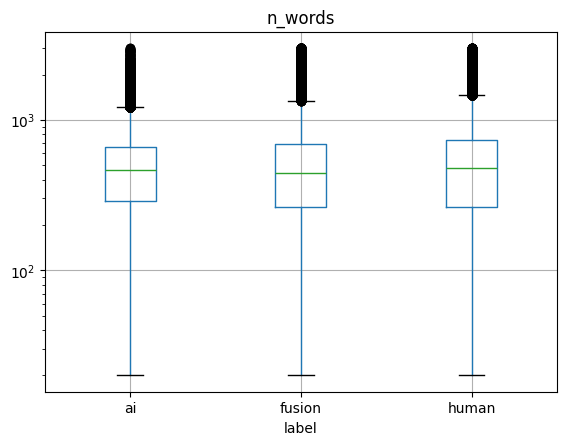


=== human ===
 Herr Präsident! Meine Damen und Herren! Es wird Sie nicht völlig verwundern, wenn ich nach drei Jahren Regierungszeit, nachdem drei Viertel dieser Regierungszeit vergangen sind, positive Bilanz ziehe für den Bundesinnenminister, gerade für die Felder Migration und innere Sicherheit. Ich will das an ganz konkreten Punkten festmachen. Fachkräfteeinwanderungsgesetz – das Stichwort ist hier heute noch

=== ai ===
 Diego's Demons Return: Is the Football Legend Losing Control? Fans have been left heartbroken and bewildered as whispers swirl about Diego Maradona's health and personal life taking a dramatic turn for the worse. Could the legendary Argentine footballer, once hailed as a hero, be slipping back into his old demons? The latest reports paint a troubling picture of a man battling both addiction and an

=== fusion ===
 Sehr geehrte Frau Präsidentin! Liebe Kolleginnen und Kollegen! 84 Prozent der Beschäftigten in der IT-Branche in Deutschland sind Männer. 84 Prozent! Ge

In [2]:
import matplotlib.pyplot as plt
print(train[LABEL].value_counts(normalize=True).round(3))

extra = [c for c in train.columns if c not in (ID, TEXT, LABEL)]
print("Додаткові колонки:", extra)
for c in extra:
    if train[c].nunique() < 30:
        print(pd.crosstab(train[c], train[LABEL], normalize="index").round(3), "\n")

train["n_words"] = train[TEXT].str.split().str.len()
print(train.groupby(LABEL)["n_words"].describe().round(0))
print("Частка текстів > 300 слів:\n", (train.n_words > 300).groupby(train[LABEL]).mean().round(3))
train.boxplot(column="n_words", by=LABEL); plt.yscale("log"); plt.suptitle(""); plt.show()

for l in LABELS:
    print(f"\n=== {l} ===\n", train[train[LABEL] == l][TEXT].iloc[0][:400])

## TF-IDF ознаки
Перетворюємо текст на числа: частоти слів/пар слів і буквосполучень (3-5 символів), зважені за TF-IDF. Векторизатори вчаться **тільки на train**, інакше буде data leakage (за це знімають бали).

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack

cut = lambda s: s.str.slice(0, 5000)   # перші 5000 символів, щоб було швидше
wv = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=300000, sublinear_tf=True)
cv = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=5, max_features=300000, sublinear_tf=True)

Xtr = hstack([wv.fit_transform(cut(tr[TEXT])), cv.fit_transform(cut(tr[TEXT]))]).tocsr()
Xva = hstack([wv.transform(cut(va[TEXT])), cv.transform(cut(va[TEXT]))]).tocsr()
Xte = hstack([wv.transform(cut(test[TEXT])), cv.transform(cut(test[TEXT]))]).tocsr()
print(Xtr.shape)

(31995, 572173)


## Моделі + маленький пошук параметрів
2 моделі (логрегресія, лінійний SVM) по 3 значення `C` (сила регуляризації). `class_weight="balanced"` допомагає рідшим класам, а це важливо для macro-F1. Найкращу логрегресію зберігаємо, бо вона дає ймовірності для ансамблю.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

grids = [("LogReg", lambda C: LogisticRegression(C=C, max_iter=300, class_weight="balanced"), [1, 10, 30]),
         ("LinearSVC", lambda C: LinearSVC(C=C, class_weight="balanced"), [0.1, 0.3, 1])]
rows, best = [], (-1, None)
for name, mk, Cs in grids:
    for C in Cs:
        m = mk(C).fit(Xtr, ytr)
        f = f1_score(yva, m.predict(Xva), average="macro")
        rows.append((name, C, round(f, 4)))
        if name == "LogReg" and f > best[0]:
            best = (f, m)
print(pd.DataFrame(rows, columns=["модель", "C", "macro-F1"]))

      модель     C  macro-F1
0     LogReg   1.0    0.8490
1     LogReg  10.0    0.8554
2     LogReg  30.0    0.8598
3  LinearSVC   0.1    0.8319
4  LinearSVC   0.3    0.8422
5  LinearSVC   1.0    0.8457


## Метрики, матриця помилок, збереження
Метрики по кожному класу й confusion matrix. Зберігаємо ймовірності (`tfidf_val.npy`, `tfidf_test.npy`) і `submission_tfidf.csv`.

              precision    recall  f1-score   support

       human      0.738     0.874     0.800      1950
          ai      0.976     0.987     0.981      3556
      fusion      0.874     0.734     0.798      2499

    accuracy                          0.880      8005
   macro avg      0.863     0.865     0.860      8005
weighted avg      0.886     0.880     0.880      8005



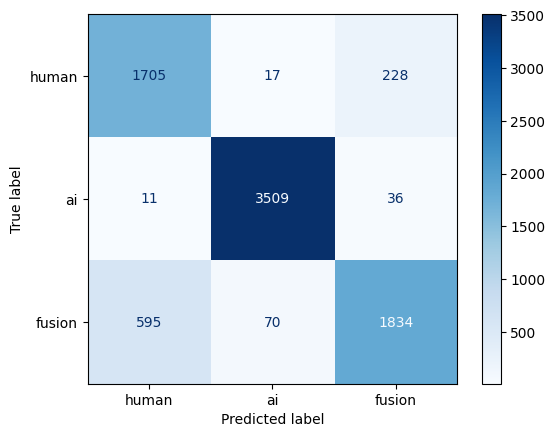

In [5]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

model = best[1]
pva = model.predict_proba(Xva)
print(classification_report(yva, pva.argmax(1), target_names=LABELS, digits=3))
ConfusionMatrixDisplay(confusion_matrix(yva, pva.argmax(1)), display_labels=LABELS).plot(cmap="Blues")
plt.show()

np.save(f"{OUT}/tfidf_val.npy", pva)
np.save(f"{OUT}/tfidf_test.npy", model.predict_proba(Xte))
save_sub(model.predict_proba(Xte), "submission_tfidf.csv")

## Що модель "бачить" (xAI)
15 слів з найбільшою вагою для кожного класу в логістичній регресії.

In [6]:
wv2 = TfidfVectorizer(min_df=5, max_features=50000, sublinear_tf=True)
lr2 = LogisticRegression(C=10, max_iter=300).fit(wv2.fit_transform(cut(tr[TEXT])), ytr)
words = np.array(wv2.get_feature_names_out())
for i, l in enumerate(LABELS):
    print(l, "->", ", ".join(words[np.argsort(-lr2.coef_[i])[:15]]))

human -> dank, urllink, student_name, vielen, conclusion, danke, have, auch, bei, able, will, petition, very, herzlichen, sehr
ai -> let, maybe, this, gotta, just, seriously, unsere, these, super, significant, potential, feels, like, about, truly
fusion -> furthermore, and, missing, reconstructed, müssen, herausforderungen, section, moreover, to, the, nur, that, beginning, argued, additionally
